# Flow encoding and the shortest waveform

A bipolar flow-encoding gradient: M0 = 0, so static spins get no phase, and M1 = 14 mT·ms²/m.
GrOpt solves for a fixed number of samples, so this example also shows how to find the shortest
duration that can meet the constraints.

In [1]:
from timeit import default_timer as timer

import numpy as np

import gropt
from gropt.plot import plot_waves

In [2]:
def flow_encode(N, project=False):
    """Flow encode with N samples at 10 us."""
    gp = gropt.GroptParams()
    gp.dt = 10e-6
    gp.N = N
    gp.vec_init_simple()
    gp.add_gmax(0.08)
    gp.add_smax(200)
    gp.add_moment(0, 0.0, project=project)
    gp.add_moment(1, 14.0, project=project)
    return gp


def moments(g, dt):
    """M0 [mT*ms/m] and M1 [mT*ms^2/m]."""
    t = np.arange(g.size) * dt
    return np.sum(g) * dt * 1e6, np.sum(g * t) * dt * 1e9

## Tolerance or exact moments

By default every constraint is enforced through the ADMM iterations: the solve is done once each moment
is within its tolerance (`tol`, 1e-6 mT·ms/m for M0). With `project=True` the moments are instead
projected onto exactly on every iteration (a null-space projection), which also takes fewer iterations.

In [3]:
for project in (False, True):
    gp = flow_encode(140, project)
    t0 = timer()
    r = gropt.solve(gp)
    t1 = timer()
    M0, M1 = moments(r.X, gp.dt)
    print(f'project={project!s:5}  converged={r.converged}  iterations={r.n_iter:4d}  '
          f'time={1e3 * (t1 - t0):4.1f} ms  M0={M0:+.1e}  M1-14={M1 - 14:+.1e}')

project=False  converged=True  iterations= 104  time= 2.4 ms  M0=+2.5e-07  M1-14=-6.8e-07
project=True   converged=True  iterations=  59  time= 0.8 ms  M0=-4.4e-15  M1-14=+0.0e+00


## Shortest duration

If a duration is feasible, every longer one is too, so a bisection over N finds the time-optimal waveform
in a few solves. A solve that does not converge counts as too short; infeasible durations run until the
iteration limit, so they are the slow part of the search.

Shortest: N = 133 (1.33 ms), search time 61 ms


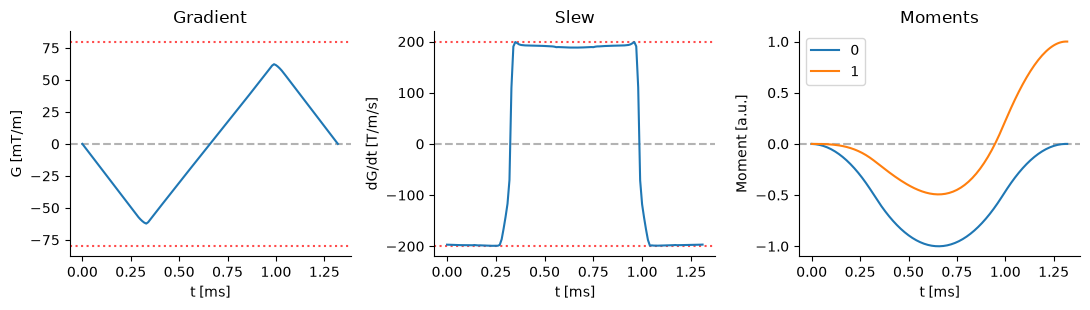

In [4]:
def shortest(make, lo, hi):
    """Smallest N in (lo, hi] whose solve converges; make(N) builds the problem."""
    best = gropt.solve(make(hi))
    if not best.converged:
        raise ValueError(f'N = {hi} is not feasible; raise hi')
    while hi - lo > 1:
        mid = (lo + hi) // 2
        r = gropt.solve(make(mid))
        if r.converged:
            hi, best = mid, r
        else:
            lo = mid
    return hi, best


t0 = timer()
N_min, r = shortest(lambda N: flow_encode(N, project=True), 50, 300)
print(f'Shortest: N = {N_min} ({N_min * 10e-3:.2f} ms), search time {1e3 * (timer() - t0):.0f} ms')
plot_waves(r.X, 10e-6, gmax=0.08, smax=200, N_cols=3, figsize=(11, 3.2), dpi=100, params={'MMT': 1})

The time-optimal waveform runs at the slew limit almost everywhere: two triangular lobes that do not
reach the gradient limit. The moment panel shows the running moments, each scaled to a peak of 1; both end
at their targets (M0 at 0).